In [1]:
# This mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive')

# TODO: Enter the foldername in your Drive where you have saved the unzipped
# assignment folder, e.g. 'icv83551/assignments/assignment1/'
FOLDERNAME = 'icv83551/assignments/assignment1/'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# This downloads the CIFAR-10 dataset to your Drive
# if it doesn't already exist.
%cd /content/drive/My\ Drive/$FOLDERNAME/icv83551/datasets/
!bash get_datasets.sh
%cd /content/drive/My\ Drive/$FOLDERNAME

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/icv83551/assignments/assignment1/icv83551/datasets
/content/drive/My Drive/icv83551/assignments/assignment1


# Softmax Classifier exercise

*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission.

In this exercise you will:
    
- Implement a fully-vectorized **loss function** for the Softmax classifier.
- Implement the fully-vectorized expression for its **analytic gradient**
- **Check your implementation** using numerical gradient
- Use a validation set to **tune the learning rate and regularization** strength
- **Optimize** the loss function with **SGD**
- **Visualize** the final learned weights


In [2]:
# Run some setup code for this notebook.
import random
import numpy as np
from icv83551.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# This is a bit of magic to make matplotlib figures appear inline in the
# notebook rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

## CIFAR-10 Data Loading and Preprocessing

In [3]:
# Load the raw CIFAR-10 data.
cifar10_dir = 'icv83551/datasets/cifar-10-batches-py'

# Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


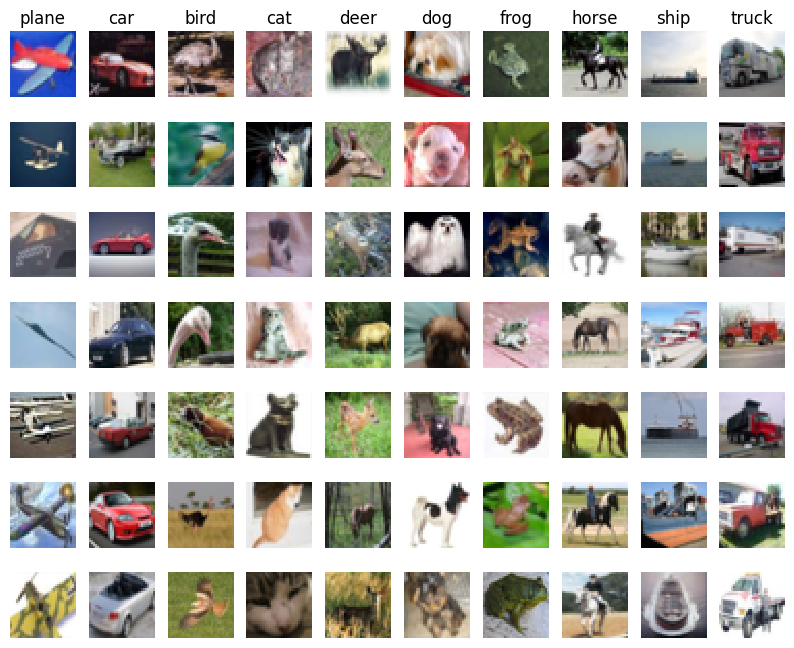

In [4]:
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# Split the data into train, val, and test sets. In addition we will
# create a small development set as a subset of the training data;
# we can use this for development so our code runs faster.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Our validation set will be num_validation points from the original
# training set.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Our training set will be the first num_train points from the original
# training set.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# We will also make a development set, which is a small subset of
# the training set.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# We use the first num_test points of the original test set as our
# test set.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,)
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (1000, 32, 32, 3)
Test labels shape:  (1000,)


In [6]:
# Preprocessing: reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# As a sanity check, print out the shapes of the data
print('Training data shape: ', X_train.shape)
print('Validation data shape: ', X_val.shape)
print('Test data shape: ', X_test.shape)
print('dev data shape: ', X_dev.shape)

Training data shape:  (49000, 3072)
Validation data shape:  (1000, 3072)
Test data shape:  (1000, 3072)
dev data shape:  (500, 3072)


[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


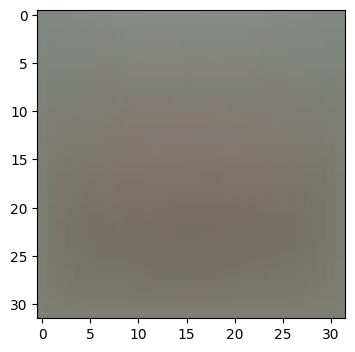

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


In [7]:
# Preprocessing: subtract the mean image
# first: compute the image mean based on the training data
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) # print a few of the elements
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # visualize the mean image
plt.show()

# second: subtract the mean image from train and test data
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

# third: append the bias dimension of ones (i.e. bias trick) so that our classifier
# only has to worry about optimizing a single weight matrix W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

## Softmax Classifier

Your code for this section will all be written inside `icv83551/classifiers/softmax.py`.

As you can see, we have prefilled the function `softmax_loss_naive` which uses for loops to evaluate the softmax loss function.

In [8]:
# Evaluate the naive implementation of the loss we provided for you:
from icv83551.classifiers.softmax import softmax_loss_naive
import time

# generate a random Softmax classifier weight matrix of small numbers
W = np.random.randn(3073, 10) * 0.0001

loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % (loss, ))

# As a rough sanity check, our loss should be something close to -log(0.1).
print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.379637
loss: 2.379637
sanity check: 2.302585


**Inline Question 1**

Why do we expect our loss to be close to -log(0.1)? Explain briefly.**

$\color{blue}{\textit Your Answer:}$


At initialization, the weight matrix $W$ is populated with small random values close to zero. Consequently, the unnormalized log probabilities (scores) for all 10 classes are approximately equal ($s \approx 0$).

Applying the Softmax function therefore yields an approximately uniform probability distribution across all classes, giving each class—including the ground truth label—a predicted probability of roughly $P(y = y_i) \approx \frac{1}{C} = \frac{1}{10} = 0.1$.

The data loss is given by the negative log-likelihood of the correct class, $L_i = -\log(P(y = y_i)) \approx -\log(0.1) \approx 2.302$. Furthermore, because the initial weights are very small, the regularization loss ($\text{reg} \cdot \|W\|_F^2$) is virtually zero, making the total loss extremely close to $-\log(0.1)$.



The `grad` returned from the function above is right now all zero. Derive and implement the gradient for the softmax loss function and implement it inline inside the function `softmax_loss_naive`. You will find it helpful to interleave your new code inside the existing function.

To check that you have correctly implemented the gradient, you can numerically estimate the gradient of the loss function and compare the numeric estimate to the gradient that you computed. We have provided code that does this for you:

In [9]:
# Once you've implemented the gradient, recompute it with the code below
# and gradient check it with the function we provided for you

# Compute the loss and its gradient at W.
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# Numerically compute the gradient along several randomly chosen dimensions, and
# compare them with your analytically computed gradient. The numbers should match
# almost exactly along all dimensions.
from icv83551.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

# do the gradient check once again with regularization turned on
# you didn't forget the regularization gradient did you?
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

numerical: 3.233933 analytic: 3.227478, relative error: 9.989948e-04
numerical: -0.507756 analytic: -0.506743, relative error: 9.988820e-04
numerical: 3.451889 analytic: 3.444999, relative error: 9.990086e-04
numerical: 2.362754 analytic: 2.358037, relative error: 9.990262e-04
numerical: 1.160352 analytic: 1.158036, relative error: 9.990592e-04
numerical: 0.686308 analytic: 0.684938, relative error: 9.990325e-04
numerical: -4.273203 analytic: -4.264674, relative error: 9.989979e-04
numerical: -0.709638 analytic: -0.708221, relative error: 9.989712e-04
numerical: -0.202783 analytic: -0.202378, relative error: 9.989682e-04
numerical: 2.266585 analytic: 2.262061, relative error: 9.990032e-04
numerical: 0.718429 analytic: 0.716995, relative error: 9.989661e-04
numerical: 1.457634 analytic: 1.454725, relative error: 9.990155e-04
numerical: 0.640670 analytic: 0.639391, relative error: 9.990971e-04
numerical: -0.811536 analytic: -0.809916, relative error: 9.989749e-04
numerical: 0.972590 anal

**Inline Question 2**

Although gradcheck is reliable softmax loss, it is possible that for SVM loss, once in a while, a dimension in the gradcheck will not match exactly. What could such a discrepancy be caused by? Is it a reason for concern? What is a simple example in one dimension where a svm loss gradient check could fail? How would change the margin affect of the frequency of this happening?

Note that SVM loss for a sample $(x_i, y_i)$ is defined as: $$L_i = \sum_{j\ne y_i}\max(0, s_j - s_{y_i} + \Delta)$$ Where $j$ iterates over all classes except the correct class $y_i$ and $s_j$ denotes the classifier score for $j^{th}$ class. $\Delta$ is a scalar margin.
*Hint: the SVM loss function is not strictly speaking differentiable.*


$\color{blue}{\textit Your Answer:}$

**Cause of Discrepancy:** The SVM hinge loss function uses a non-smooth $\max(0, \cdot)$ operation, introducing non-differentiable "kinks" wherever $s_j - s_{y_i} + \Delta = 0$. Numerical gradient checking evaluates $\frac{f(w + h) - f(w - h)}{2h}$. When a dimension resides within a distance of $h$ from this kink, the finite difference evaluation spans across the boundary (where one side is 0 and the other has a non-zero slope). This yields an averaged numerical slope that does not match the exact directional sub-gradient computed analytically.

2. **Is it a reason for concern?** No, it is not a reason for concern. The set of points where the function is non-differentiable has measure zero in continuous parameter space. During gradient descent / SGD, hitting these exact kinks is extremely rare and does not hinder optimization (analogous to the behavior of ReLU activations).

3. **Simple 1D Example:** Consider the simple function $f(x) = \max(0, x)$ with step size $h = 10^{-4}$. If we evaluate the gradient at $x = 10^{-6}$:
   * The analytical gradient is $1$, since $x > 0$.
   * The numerical gradient is: $\frac{f(10^{-6} + 10^{-4}) - f(10^{-6} - 10^{-4})}{2 \cdot 10^{-4}} = \frac{1.01 \cdot 10^{-4} - 0}{2 \cdot 10^{-4}} = 0.505$. The relative error between $1$ and $0.505$ is nearly $33\%$, causing a gradcheck failure despite correct implementation.

4. **Effect of Changing the Margin ($\Delta$):** Changing the margin $\Delta$ does not affect the frequency of these discrepancies. Altering $\Delta$ merely shifts the translation threshold where the kink occurs ($s_j - s_{y_i} = -\Delta$). Because the weights and scores are continuous variables, the probability of falling into the "kink zone" of width $2h$ depends solely on the step size $h$, not on the constant offset $\Delta$.



In [10]:
# Next implement the function softmax_loss_vectorized; for now only compute the loss;
# we will implement the gradient in a moment.
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from icv83551.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, _ = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))

# The losses should match but your vectorized implementation should be much faster.
print('difference: %f' % (loss_naive - loss_vectorized))

Naive loss: 2.379637e+00 computed in 0.080785s
Vectorized loss: 2.374887e+00 computed in 0.010108s
difference: 0.004750


In [11]:
# Complete the implementation of softmax_loss_vectorized, and compute the gradient
# of the loss function in a vectorized way.

# The naive implementation and the vectorized implementation should match, but
# the vectorized version should still be much faster.
tic = time.time()
_, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

# The loss is a single number, so it is easy to compare the values computed
# by the two implementations. The gradient on the other hand is a matrix, so
# we use the Frobenius norm to compare them.
difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

Naive loss and gradient: computed in 0.108457s
Vectorized loss and gradient: computed in 0.008490s
difference: 0.000000


### Stochastic Gradient Descent

We now have vectorized and efficient expressions for the loss, the gradient and our gradient matches the numerical gradient. We are therefore ready to do SGD to minimize the loss. Your code for this part will be written inside `icv83551/classifiers/linear_classifier.py`.

In [12]:
# In the file linear_classifier.py, implement SGD in the function
# LinearClassifier.train() and then run it with the code below.
from icv83551.classifiers import Softmax
softmax = Softmax()
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

iteration 0 / 1500: loss 777.503451
iteration 100 / 1500: loss 285.504744
iteration 200 / 1500: loss 105.773112
iteration 300 / 1500: loss 39.981505
iteration 400 / 1500: loss 15.939068
iteration 500 / 1500: loss 7.191051
iteration 600 / 1500: loss 3.961412
iteration 700 / 1500: loss 2.841538
iteration 800 / 1500: loss 2.331713
iteration 900 / 1500: loss 2.084106
iteration 1000 / 1500: loss 2.124569
iteration 1100 / 1500: loss 2.115195
iteration 1200 / 1500: loss 2.047104
iteration 1300 / 1500: loss 2.065008
iteration 1400 / 1500: loss 2.167829
That took 12.792897s


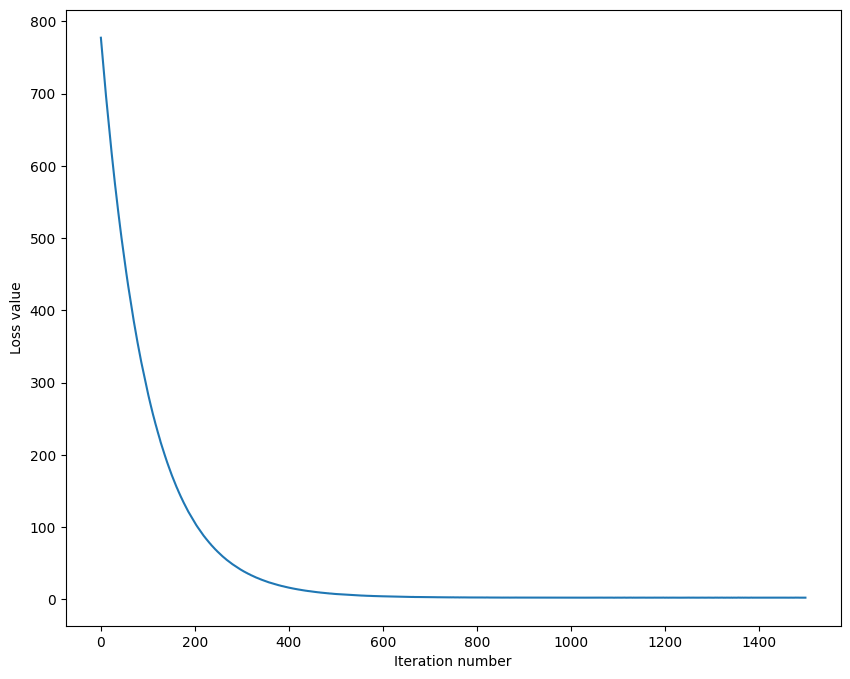

In [13]:
# A useful debugging strategy is to plot the loss as a function of
# iteration number:
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

In [14]:
# Write the LinearClassifier.predict function and evaluate the performance on
# both the training and validation set
# You should get validation accuracy of about 0.34 (> 0.33).
y_train_pred = softmax.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = softmax.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.328184
validation accuracy: 0.340000


In [15]:
# Save the trained model for autograder.
softmax.save("softmax.npy")

softmax.npy saved.


In [16]:
# Use the validation set to tune hyperparameters (regularization strength and
# learning rate). You should experiment with different ranges for the learning
# rates and regularization strengths; if you are careful you should be able to
# get a classification accuracy of about 0.365 (> 0.36) on the validation set.

# Note: you may see runtime/overflow warnings during hyper-parameter search.
# This may be caused by extreme values, and is not a bug.

# results is dictionary mapping tuples of the form
# (learning_rate, regularization_strength) to tuples of the form
# (training_accuracy, validation_accuracy). The accuracy is simply the fraction
# of data points that are correctly classified.
results = {}
best_val = -1   # The highest validation accuracy that we have seen so far.
best_softmax = None # The Softmax object that achieved the highest validation rate.

################################################################################
# TODO:                                                                        #
# Write code that chooses the best hyperparameters by tuning on the validation #
# set. For each combination of hyperparameters, train a Softmax on the.        #
# training set, compute its accuracy on the training and validation sets, and  #
# store these numbers in the results dictionary. In addition, store the best   #
# validation accuracy in best_val and the Softmax object that achieves this.   #
# accuracy in best_softmax.                                                    #
#                                                                              #
# Hint: You should use a small value for num_iters as you develop your         #
# validation code so that the classifiers don't take much time to train; once  #
# you are confident that your validation code works, you should rerun the      #
# code with a larger value for num_iters.                                      #
################################################################################

# Provided as a reference. You may or may not want to change these hyperparameters
learning_rates = [1e-7, 1e-6]
regularization_strengths = [2.5e4, 1e4]

for lr in learning_rates:
    for reg in regularization_strengths:
        sm = Softmax()
        sm.train(X_train, y_train, learning_rate=lr, reg=reg, num_iters=1000, batch_size=200, verbose=False)

        y_train_pred = sm.predict(X_train)
        train_accuracy = np.mean(y_train == y_train_pred)

        y_val_pred = sm.predict(X_val)
        val_accuracy = np.mean(y_val == y_val_pred)

        results[(lr, reg)] = (train_accuracy, val_accuracy)

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = sm

# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved during cross-validation: %f' % best_val)

lr 1.000000e-07 reg 1.000000e+04 train accuracy: 0.331163 val accuracy: 0.334000
lr 1.000000e-07 reg 2.500000e+04 train accuracy: 0.332224 val accuracy: 0.346000
lr 1.000000e-06 reg 1.000000e+04 train accuracy: 0.354020 val accuracy: 0.368000
lr 1.000000e-06 reg 2.500000e+04 train accuracy: 0.322592 val accuracy: 0.333000
best validation accuracy achieved during cross-validation: 0.368000


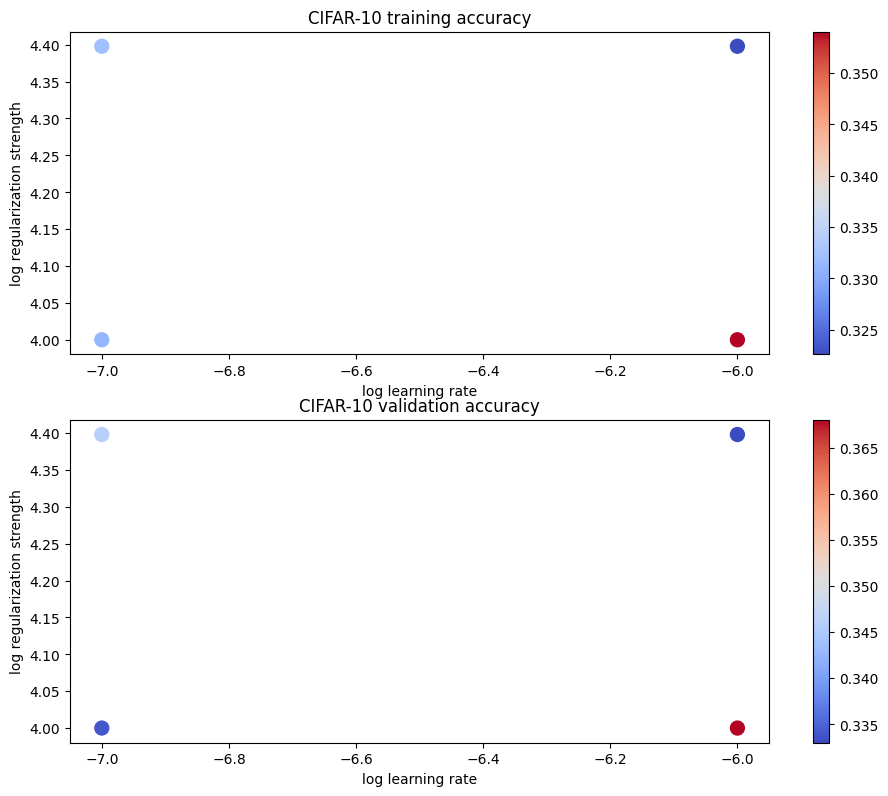

In [17]:
# Visualize the cross-validation results
import math
import pdb

# pdb.set_trace()

x_scatter = [math.log10(x[0]) for x in results]
y_scatter = [math.log10(x[1]) for x in results]

# plot training accuracy
marker_size = 100
colors = [results[x][0] for x in results]
plt.subplot(2, 1, 1)
plt.tight_layout(pad=3)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 training accuracy')

# plot validation accuracy
colors = [results[x][1] for x in results] # default size of markers is 20
plt.subplot(2, 1, 2)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 validation accuracy')
plt.show()

In [18]:
# Evaluate the best softmax on test set
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print('Softmax classifier on raw pixels final test set accuracy: %f' % test_accuracy)

Softmax classifier on raw pixels final test set accuracy: 0.344000


In [19]:
# Save best softmax model
best_softmax.save("best_softmax.npy")

best_softmax.npy saved.


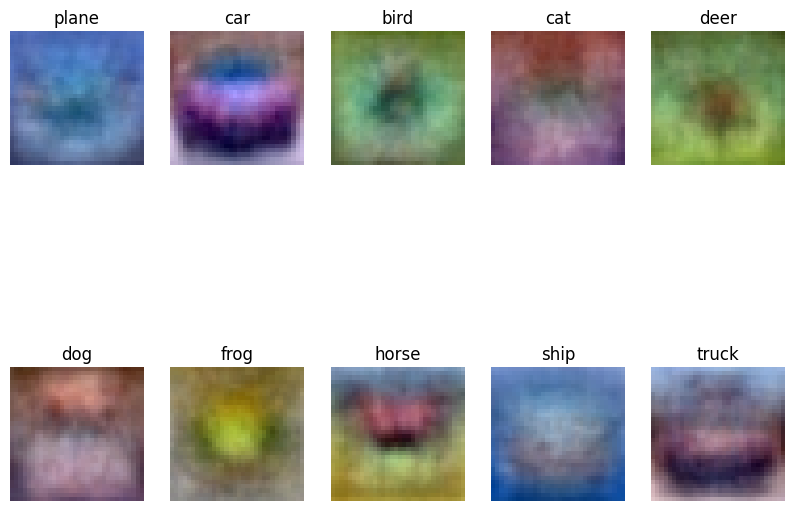

In [20]:
# Visualize the learned weights for each class.
# Depending on your choice of learning rate and regularization strength, these may
# or may not be nice to look at.
w = best_softmax.W[:-1,:] # strip out the bias
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Rescale the weights to be between 0 and 255
    wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'))
    plt.axis('off')
    plt.title(classes[i])

**Inline question 3**

Describe what your visualized Softmax classifier weights look like, and offer a brief explanation for why they look the way they do.

$\color{blue}{\textit Your Answer:}$

1. **What the weights look like:** The visualized weights resemble blurry, averaged templates (prototypes) of the objects and their typical surrounding environments:
   - Background colors dominate where context is consistent, such as strong blue tones for planes (sky) and ships (water), and green/brown patches for frogs and deer (grass/foliage).
   - Some templates reveal coarse structural silhouettes. For example, the `car` template exhibits a front-facing vehicle windshield with headlights, while the `horse` template often shows an averaged "two-headed" silhouette because horses appear facing both left and right in the dataset.

2. **Why they look this way:** A linear classifier maps raw pixel inputs directly to class scores via a single linear dot product ($w_c^T x + b_c$). Because it lacks hidden layers and nonlinear activations, it is constrained to learn only a single template per class. Consequently, the optimization forces each weight vector to represent an average summary of all training samples in that category, capturing dominant colors, canonical backgrounds, and recurring spatial structures rather than pose-invariant or fine-grained features.


**Inline Question 4** - *True or False*

Suppose the overall training loss is defined as the sum of the per-datapoint loss over all training examples. It is possible to add a new datapoint to a training set that would change the softmax loss, but leave the SVM loss unchanged.

$\color{blue}{\textit Your Answer:}$  True


$\color{blue}{\textit Your Explanation:}$

- **SVM Loss:** The SVM hinge loss operates with a threshold margin $\Delta$:
  $$L_{i,\text{SVM}} = \sum_{j \neq y_i} \max(0, s_j - s_{y_i} + \Delta)$$
  If a new datapoint is correctly classified such that the score of the correct class exceeds all other class scores by at least the margin $\Delta$ (i.e., $s_{y_i} \ge s_j + \Delta$ for all $j \neq y_i$), every term in the sum is $0$. Thus, $L_{i,\text{SVM}} = 0$, adding nothing to the overall training loss and leaving it completely unchanged.

- **Softmax Loss:** The Softmax cross-entropy loss is defined as:
  $$L_{i,\text{Softmax}} = -\log(P(y_i)) = -\log\left(\frac{e^{s_{y_i}}}{\sum_j e^{s_j}}\right)$$
  For any finite scores, the predicted probability $P(y_i)$ is strictly less than $1$ (it only approaches $1$ as $s_{y_i} \to \infty$). Consequently, $-\log(P(y_i)) > 0$ strictly holds for all real-valued inputs. Adding this datapoint will always contribute a positive non-zero value to the total sum, thereby changing the overall softmax loss.